## Assigment numero 1 corso ISPR 2024-2025

In [10]:
# Import usefull for the analysis of the samples of the instruments
import librosa
import numpy as np
import matplotlib.pyplot as plt

From the dataset 'all samples' available at the following link: https://philharmonia.co.uk/resources/sound-samples/, I selected five instruments: banjo, guitar, flute, saxophone, and trumpet. The purpose of this analysis is to determine whether, by analyzing the spectrograms of the notes, it is possible to identify the instrument that produced them.

## Computing the Spectrogram

The first step to achieve our goal is to compute the spectrograms of the notes played by the selected instruments.

The libraries used for computing the spectrograms were librosa (a Python library for audio analysis), matplotlib (a Python library for plotting graphs), and numpy (a Python library for manipulating vectors and matrices).

To compute the spectrograms, I first loaded the MP3 files using the librosa.load function. Then, I used librosa's stft function to compute the Short-Time Fourier Transform (STFT), which transforms the signal from the time domain to the frequency domain. The final step was to convert the amplitude from Hertz (Hz) to decibels (dB). Finally, using matplotlib, I plotted the spectrogram of each file, where each file represents a note played by an instrument.

The STFT was computed using a Blackman window. I chose the Blackman window because it is well-suited for harmonic analysis, which is what I performed. The STFT is calculated over time; specifically, the window function slides over the time signal, and the signal within that window is multiplied by the window function before the Fourier Transform is calculated. The other parameters of the stft function in librosa were left at their default values, as they are suitable for general audio analysis. Detailed explanations of each parameter can be found in the official librosa documentation at this link: https://librosa.org/doc/main/generated/librosa.stft.html.

In [1]:
def plot_multi_file_spectrograms(audio_files):
    

    #here we are loading the mp3 file of the note and we want to see all the notes take into consideration
    # in different subplot
    num_files = len(audio_files)
    plt.figure(figsize=(15, 5 * num_files))

    for i, audio_file in enumerate(audio_files):
        #we load the file mp3 of the note
        y, sr = librosa.load(audio_file)
        # we calculate the short furier transformation
        D = librosa.stft(y,window='blackman')
        # we take the amplitude to decibel
        S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

        # her we create the subplot
        plt.subplot(num_files, 1, i + 1)
        librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log')
        plt.colorbar(format='%+2.0f dB')
        plt.title(f'Spectrogram: {audio_file}')

    plt.tight_layout()
    plt.show()

The function in the cell below is similar to the one above. In fact, it computes the same spectrograms but highlights the harmonics and plots their values on the graph. To achieve this, the function searches for the peaks in the power spectrum and annotates these values on the spectrogram. To find the peaks, I used the *scipy.signal.find_peaks()* function. I set the prominence to 10 to clearly distinguish significant peaks and the distance to 5 samples. This ensures that each peak is separated by at least 5 samples, excluding minor variations of the previous peak.

In [ ]:
import librosa
import librosa.display
from scipy import signal

def plot_multi_file_spectrograms_with_harmonic_values(audio_files):
    """
    Plots spectrograms for multiple audio files with harmonic frequency values annotated.
    """

    num_files = len(audio_files)
    plt.figure(figsize=(15, 5 * num_files))

    for i, audio_file in enumerate(audio_files):
        y, sr = librosa.load(audio_file)
        D = librosa.stft(y, window='blackman')
        S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

        plt.subplot(num_files, 1, i + 1)
        librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log')
        plt.colorbar(format='%+2.0f dB')
        plt.title(f'Spectrogram: {audio_file}')

        # Calcola lo spettro di potenza medio
        power_spectrum = np.mean(np.abs(D) ** 2, axis=1)
        freqs = librosa.fft_frequencies(sr=sr, n_fft=D.shape[0] * 2 - 2)

        # Trova i picchi (armonici)
        peaks, _ = signal.find_peaks(power_spectrum, prominence=10, distance=5)  # Regola prominence e distance

        # Annotate le frequenze delle armoniche
        for peak in peaks:
            freq = freqs[peak]
            time_index = 0  # Posiziona l'annotazione all'inizio del tempo
            plt.annotate(f'{freq:.0f} Hz', xy=(time_index, freq), xytext=(time_index - 0.25, freq),
                         textcoords='data', ha='left', va='center', fontsize=8)

    plt.tight_layout()
    plt.show()


Using the functions in the cells above, I was able to calculate and plot the spectrograms of the various notes played by each instrument. I applied these functions to the notes of every instrument considered in this analysis.

To facilitate comparison of the different notes, I have included an image (taken from the page available at this link: https://mixbutton.com/music-tools/frequency-and-pitch/music-note-to-frequency-chart) that displays the frequencies of the notes, including octave information, relevant to the notes used in this analysis.

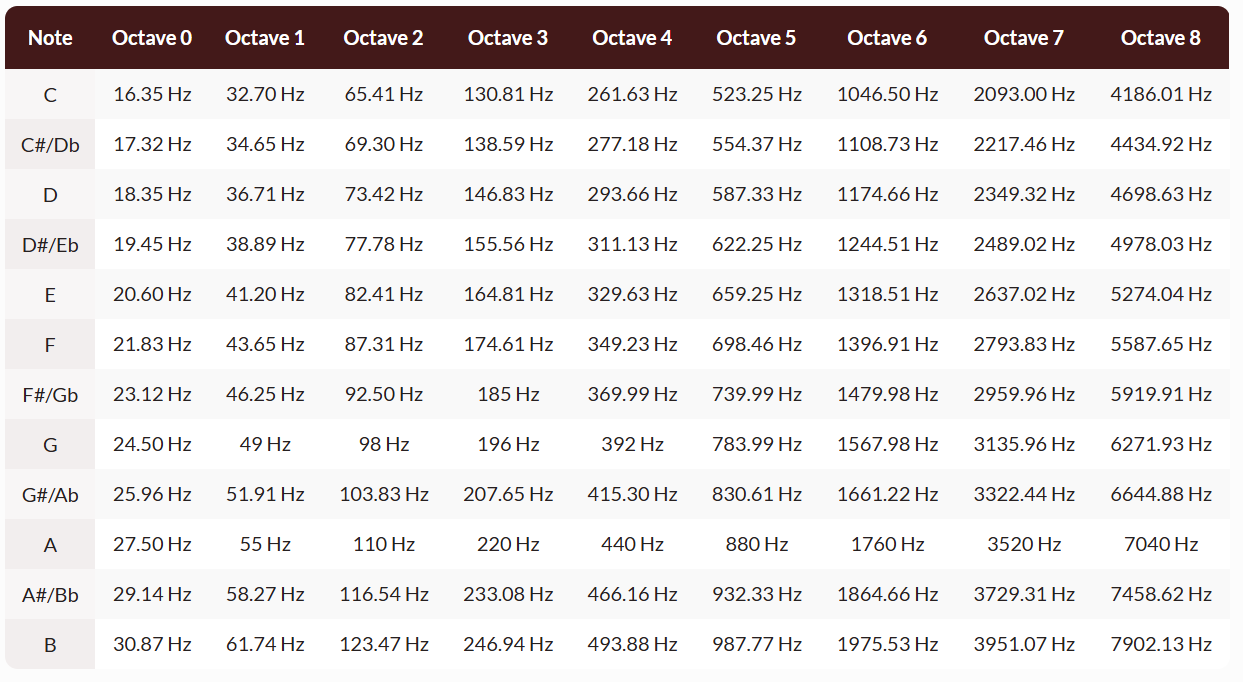

In [3]:
from IPython import  display

display.Image('frequancies.png')

## Banjo

I began by studying the case of the banjo. This is the first instrument I considered, a string instrument. I chose two string instruments (banjo and guitar) and three wind instruments (flute, saxophone, and trumpet). For the banjo and guitar, we selected the same notes to facilitate comparison. The notes considered for both the banjo and guitar are: A4, B4, C3, D3, F4, and G3. The number following each note represents the octave played, and each octave corresponds to a specific frequency.

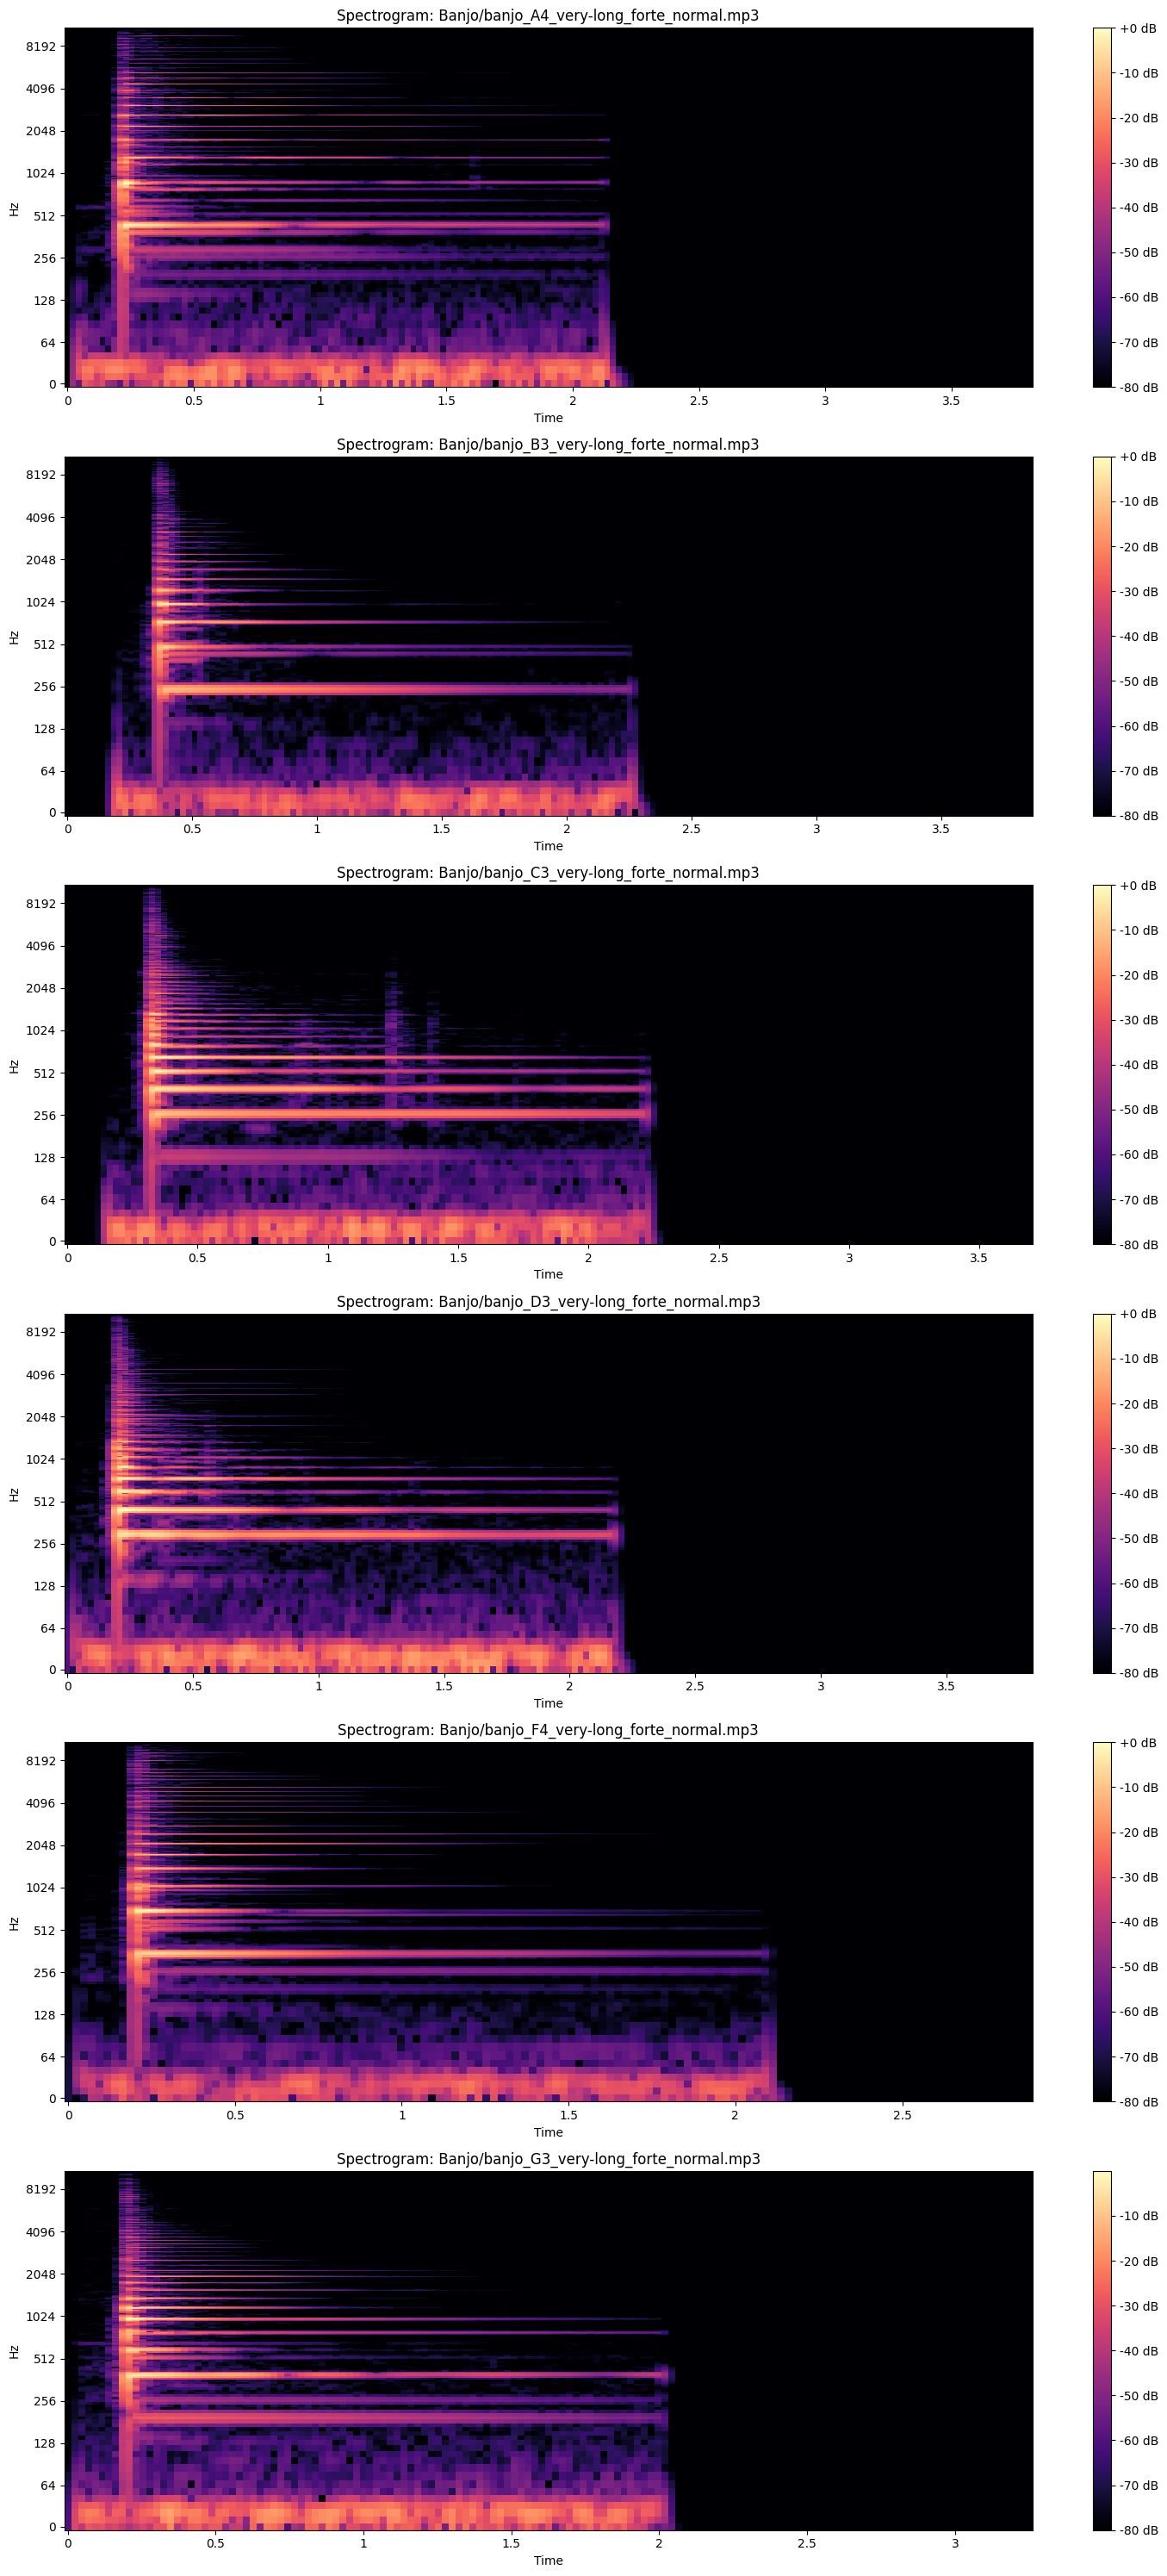

In [4]:
banjo1= 'Banjo/banjo_A4_very-long_forte_normal.mp3'
banjo2= 'Banjo/banjo_B3_very-long_forte_normal.mp3'
banjo3= 'Banjo/banjo_C3_very-long_forte_normal.mp3'
banjo4= 'Banjo/banjo_D3_very-long_forte_normal.mp3'
banjo5= 'Banjo/banjo_F4_very-long_forte_normal.mp3'
banjo6= 'Banjo/banjo_G3_very-long_forte_normal.mp3'

banjos=[banjo1,banjo2,banjo3,banjo4,banjo5,banjo6]

plot_multi_file_spectrograms(banjos)

### Observations on the results Obtained

In these spectrograms, we can clearly see the harmonics, represented by the horizontal lines. The most prominent lines correspond to the characteristic frequencies of the notes (the values are reported in the table above). We observe a typical harmonic behavior for the banjo, with higher intensity, indicated by the bright colors, even in the higher frequencies. This is due to the physical composition of the instrument. Another characteristic aspect of the banjo is the rapid decrease in the intensity of the harmonics over time; the lines representing the harmonics are relatively short and fade shortly after the onset.

## Guitar

In this section, I proceeded with the study of the same notes considered for the banjo, but played by the guitar this time. I used the same function to compute the Fourier Transform, as explained previously, and the results are reported below.

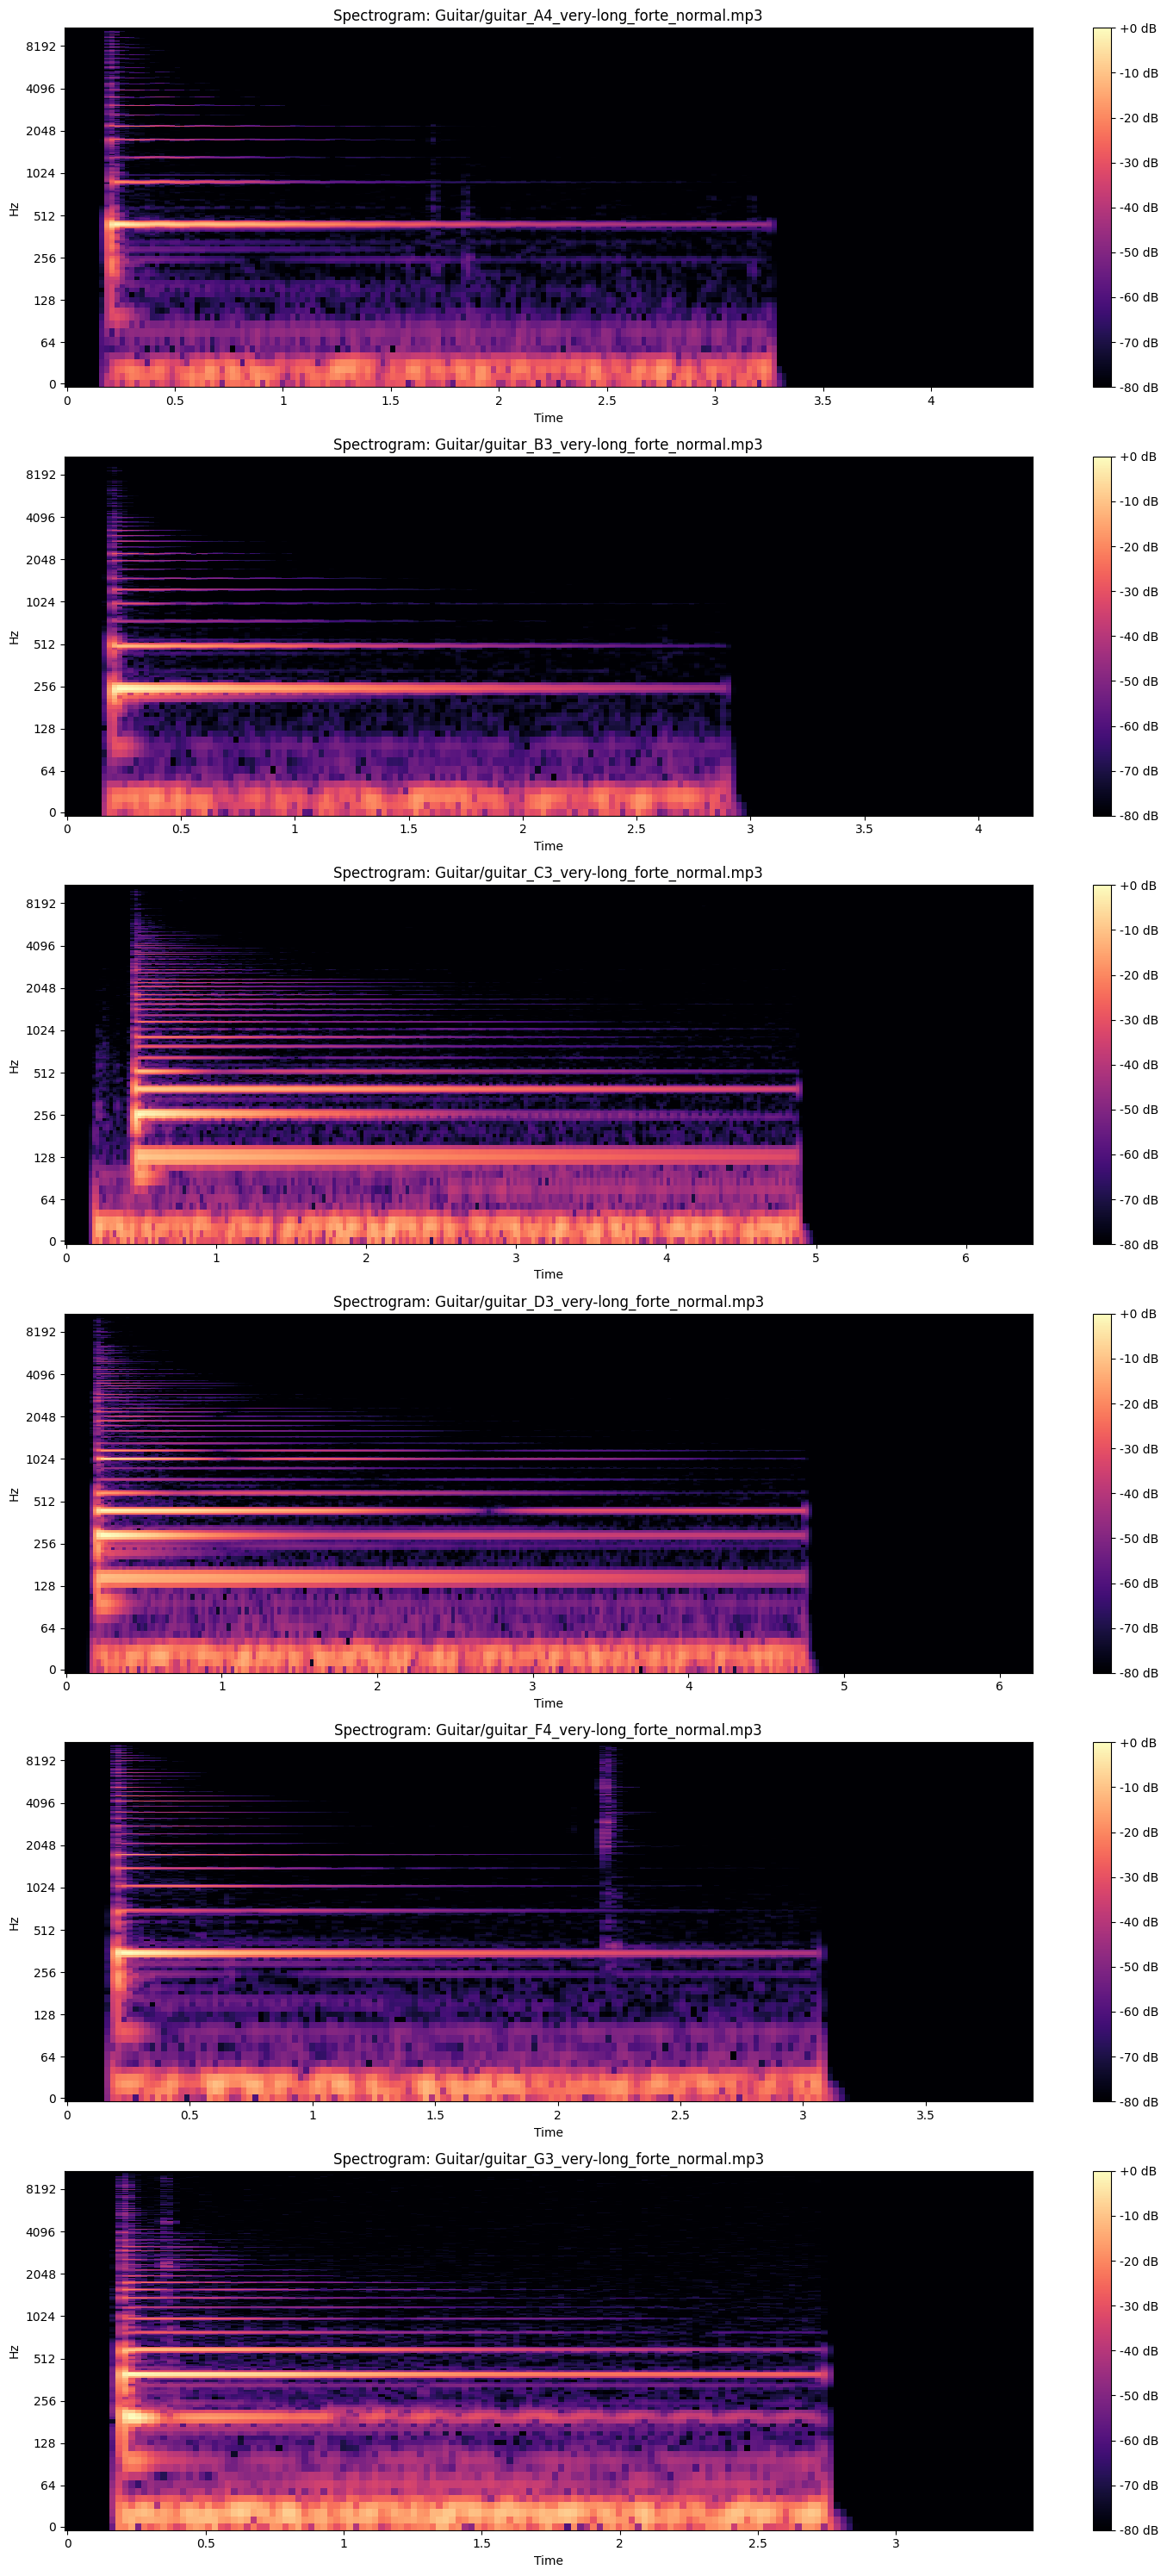

In [5]:
guitar1= 'Guitar/guitar_A4_very-long_forte_normal.mp3'
guitar2= 'Guitar/guitar_B3_very-long_forte_normal.mp3'
guitar3= 'Guitar/guitar_C3_very-long_forte_normal.mp3'
guitar4= 'Guitar/guitar_D3_very-long_forte_normal.mp3'
guitar5= 'Guitar/guitar_F4_very-long_forte_normal.mp3'
guitar6= 'Guitar/guitar_G3_very-long_forte_normal.mp3'

guitars=[guitar1,guitar2,guitar3,guitar4,guitar5,guitar6]

plot_multi_file_spectrograms(guitars)

### Observations on the Results Obtained

Similar to the banjo, the harmonics are clearly displayed in these spectrograms. The fundamental frequencies for each note align with the values reported in the table above. Upon closer inspection, we observe a similar harmonic pattern to that of the banjo. The main difference lies in the note duration; the lines representing the harmonics are longer compared to those of the banjo. This variation is attributed to the different anatomy of the two instruments, specifically the structure of the soundbox, which affects the note's duration.


## Wind instrument

In this section, we begin the study of the wind instruments. The dataset does not contain the same notes as those for the string instruments, so I decided to select seven different notes for the wind instruments. Specifically, I selected: A3, A4, A5, B3, C4, D4, and G3. As with the string instruments, the numbers following the note names represent the octaves being played.

## Clarinet

In this section, I studied the first wind instrument from those I considered: the clarinet. Below are the spectrograms of the notes played by the clarinet, including some spectrograms where the harmonic frequencies are highlighted.

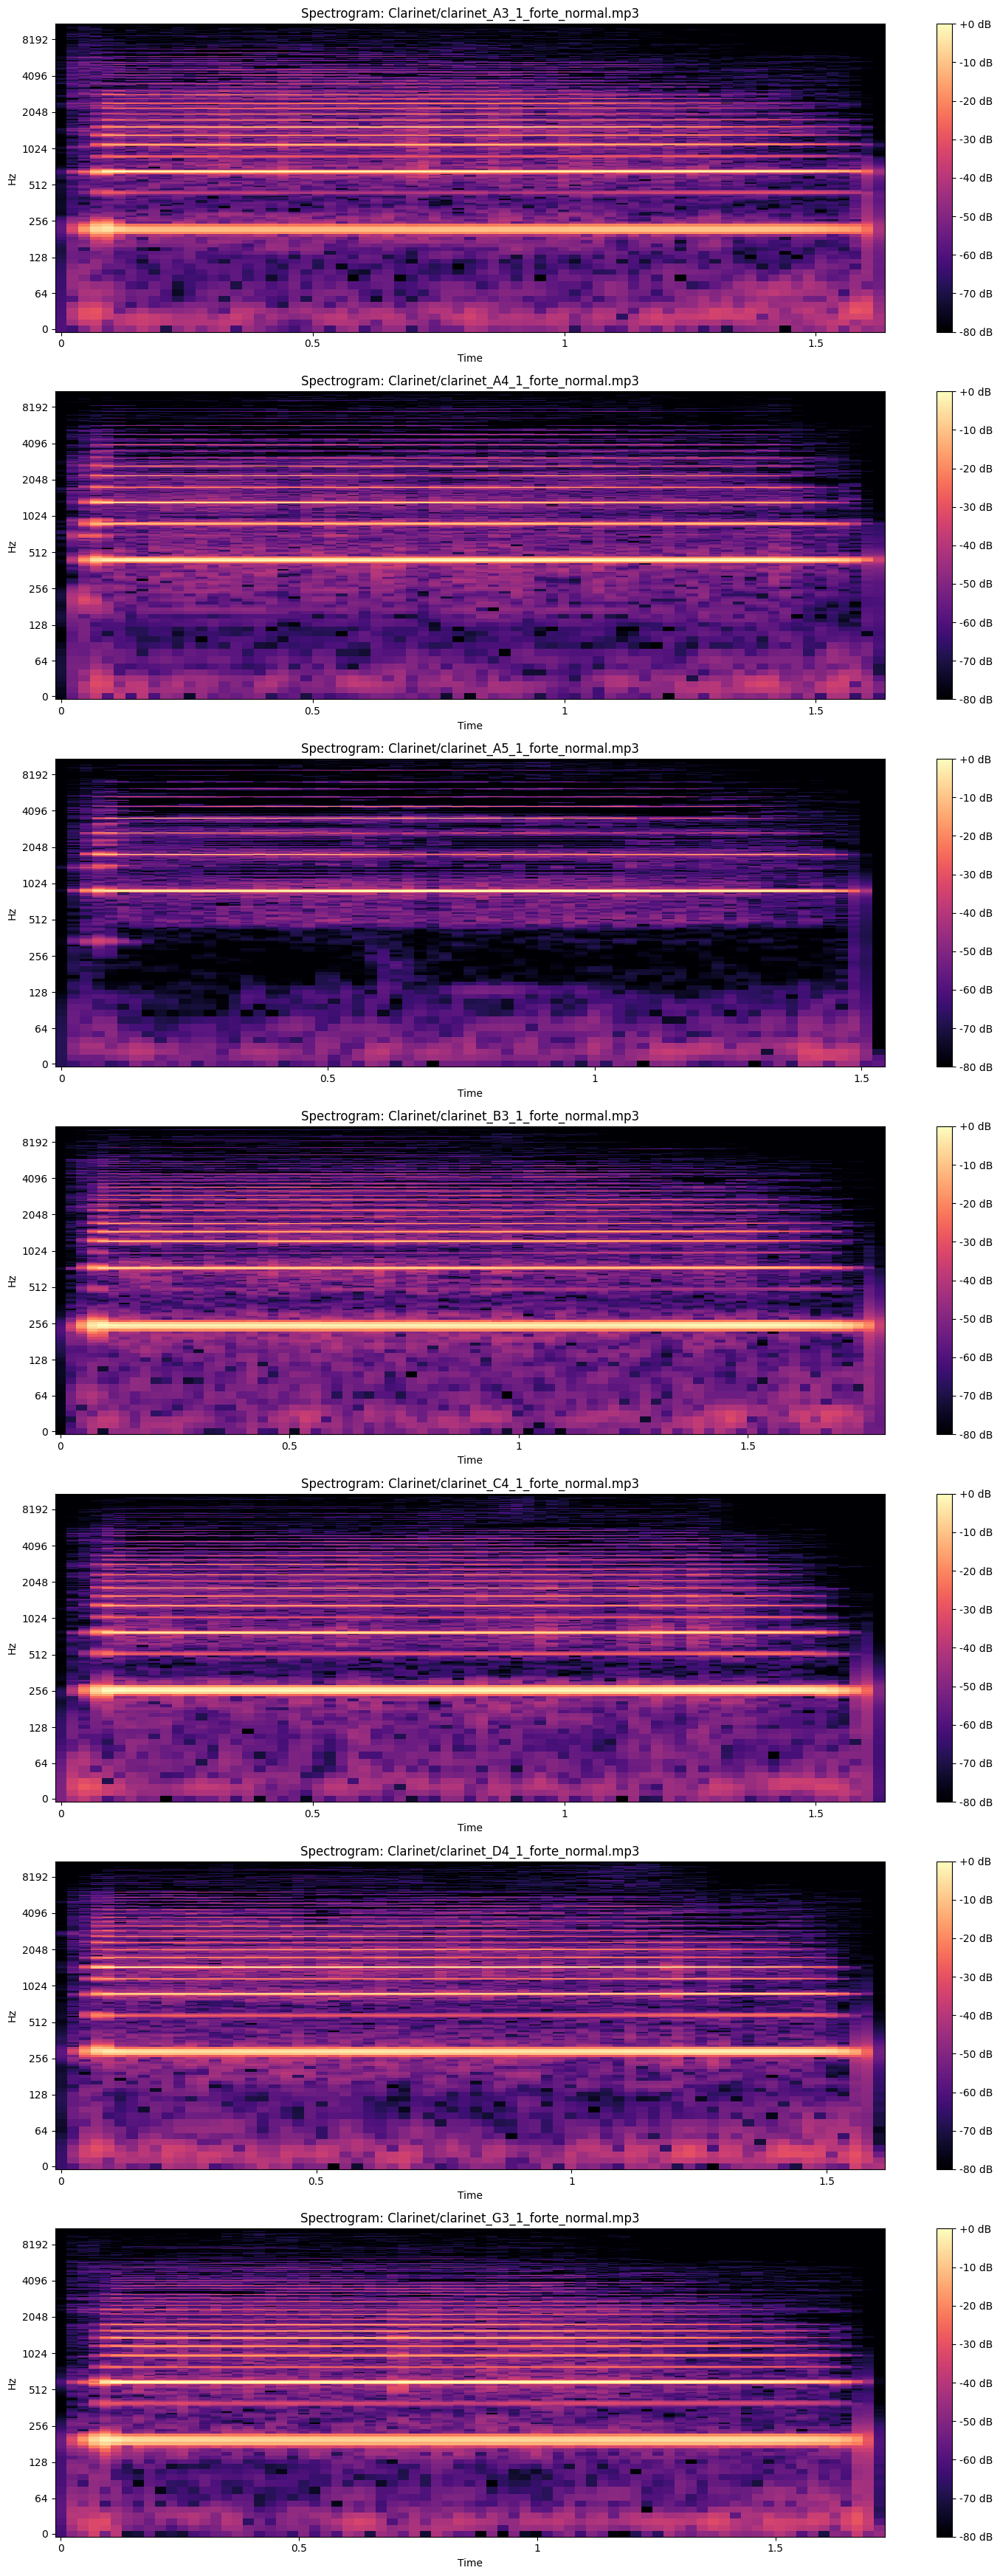

In [6]:
clarinet= 'Clarinet/clarinet_A3_1_forte_normal.mp3'
clarinet1= 'Clarinet/clarinet_A4_1_forte_normal.mp3'
clarinet2= 'Clarinet/clarinet_A5_1_forte_normal.mp3'
clarinet3= 'Clarinet/clarinet_B3_1_forte_normal.mp3'
clarinet4= 'Clarinet/clarinet_C4_1_forte_normal.mp3'
clarinet5= 'Clarinet/clarinet_D4_1_forte_normal.mp3'
clarinet6= 'Clarinet/clarinet_G3_1_forte_normal.mp3'

clarinrtes= [clarinet, clarinet1,clarinet2,clarinet3,clarinet4,clarinet5,clarinet6]

plot_multi_file_spectrograms(clarinrtes)

The clarinet has a notable characteristic. In many cases, the harmonics of the clarinet have odd frequency multiples (as documented in a study by the UNSW of Sydney: https://www.phys.unsw.edu.au/music/clarinet/G4.html). Therefore, I decided to print the harmonic frequency values to observe if this phenomenon occurred in the notes I considered. The results obtained are plotted in the cell below.

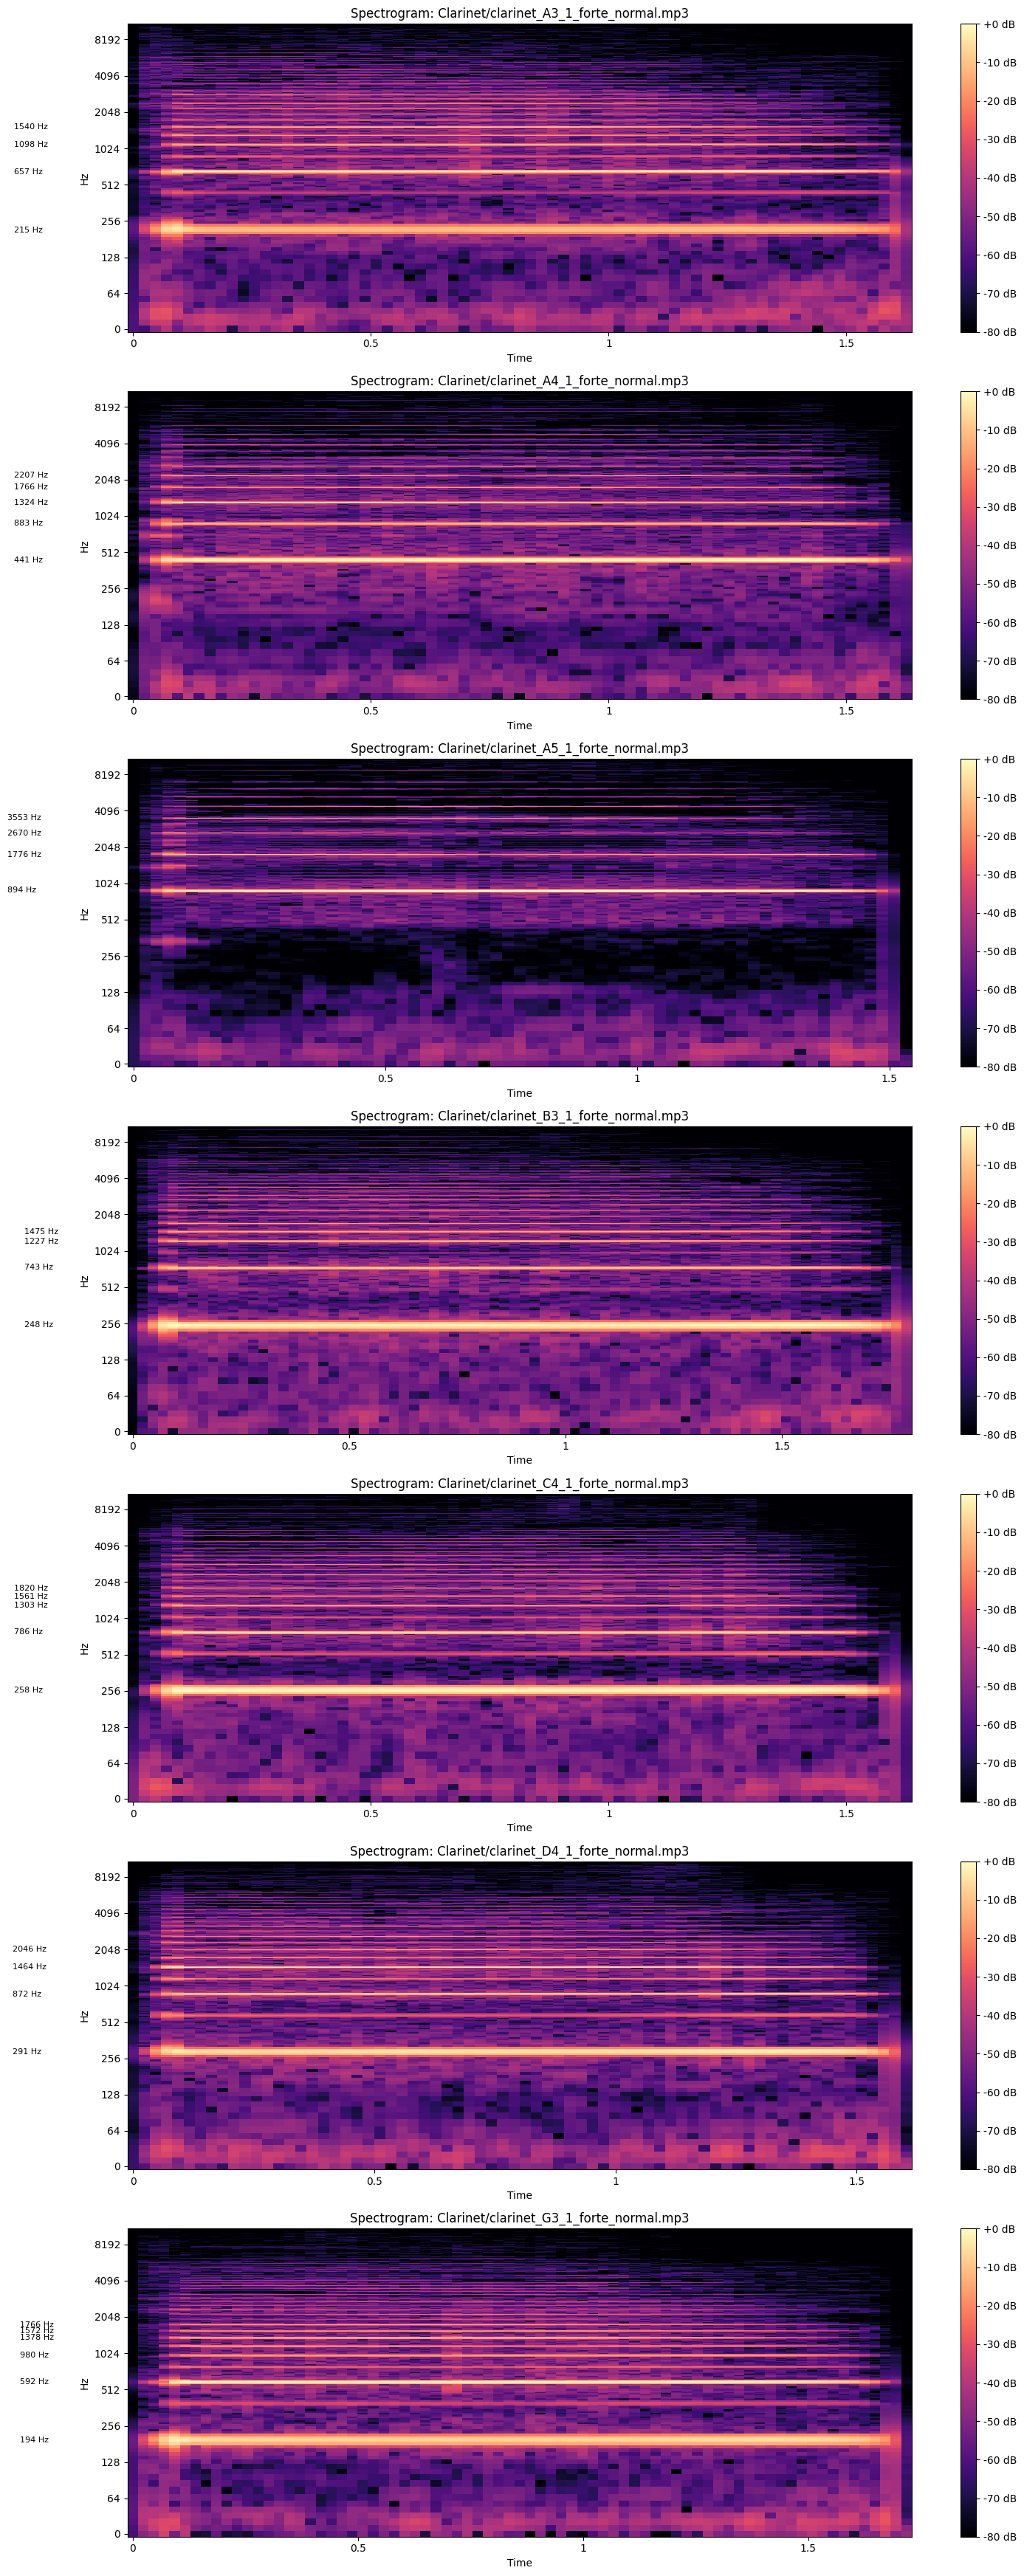

In [7]:
plot_multi_file_spectrograms_with_harmonic_values(clarinrtes)

### Observations on the Results Obtained

Similar to the guitar and banjo, the harmonics are clearly visible in the spectrograms above, which are from the clarinet. As with the guitar and banjo, the spectrograms show higher values at the characteristic frequencies of the notes played, as reported in the table above. We can also observe some characteristics specific to the clarinet. For example, we note that, generally, the frequency values are higher for odd harmonics, a typical behavior of the clarinet. However, this is not consistent across all spectrograms. This discrepancy could be attributed to noise, note stabilization issues, or variations in playing technique.

## Saxophone

In this section, I proceed with the analysis of the second wind instrument, the saxophone. Specifically, the cell below displays the spectrograms of the notes produced by the saxophone. The notes considered are the same as those for the clarinet.

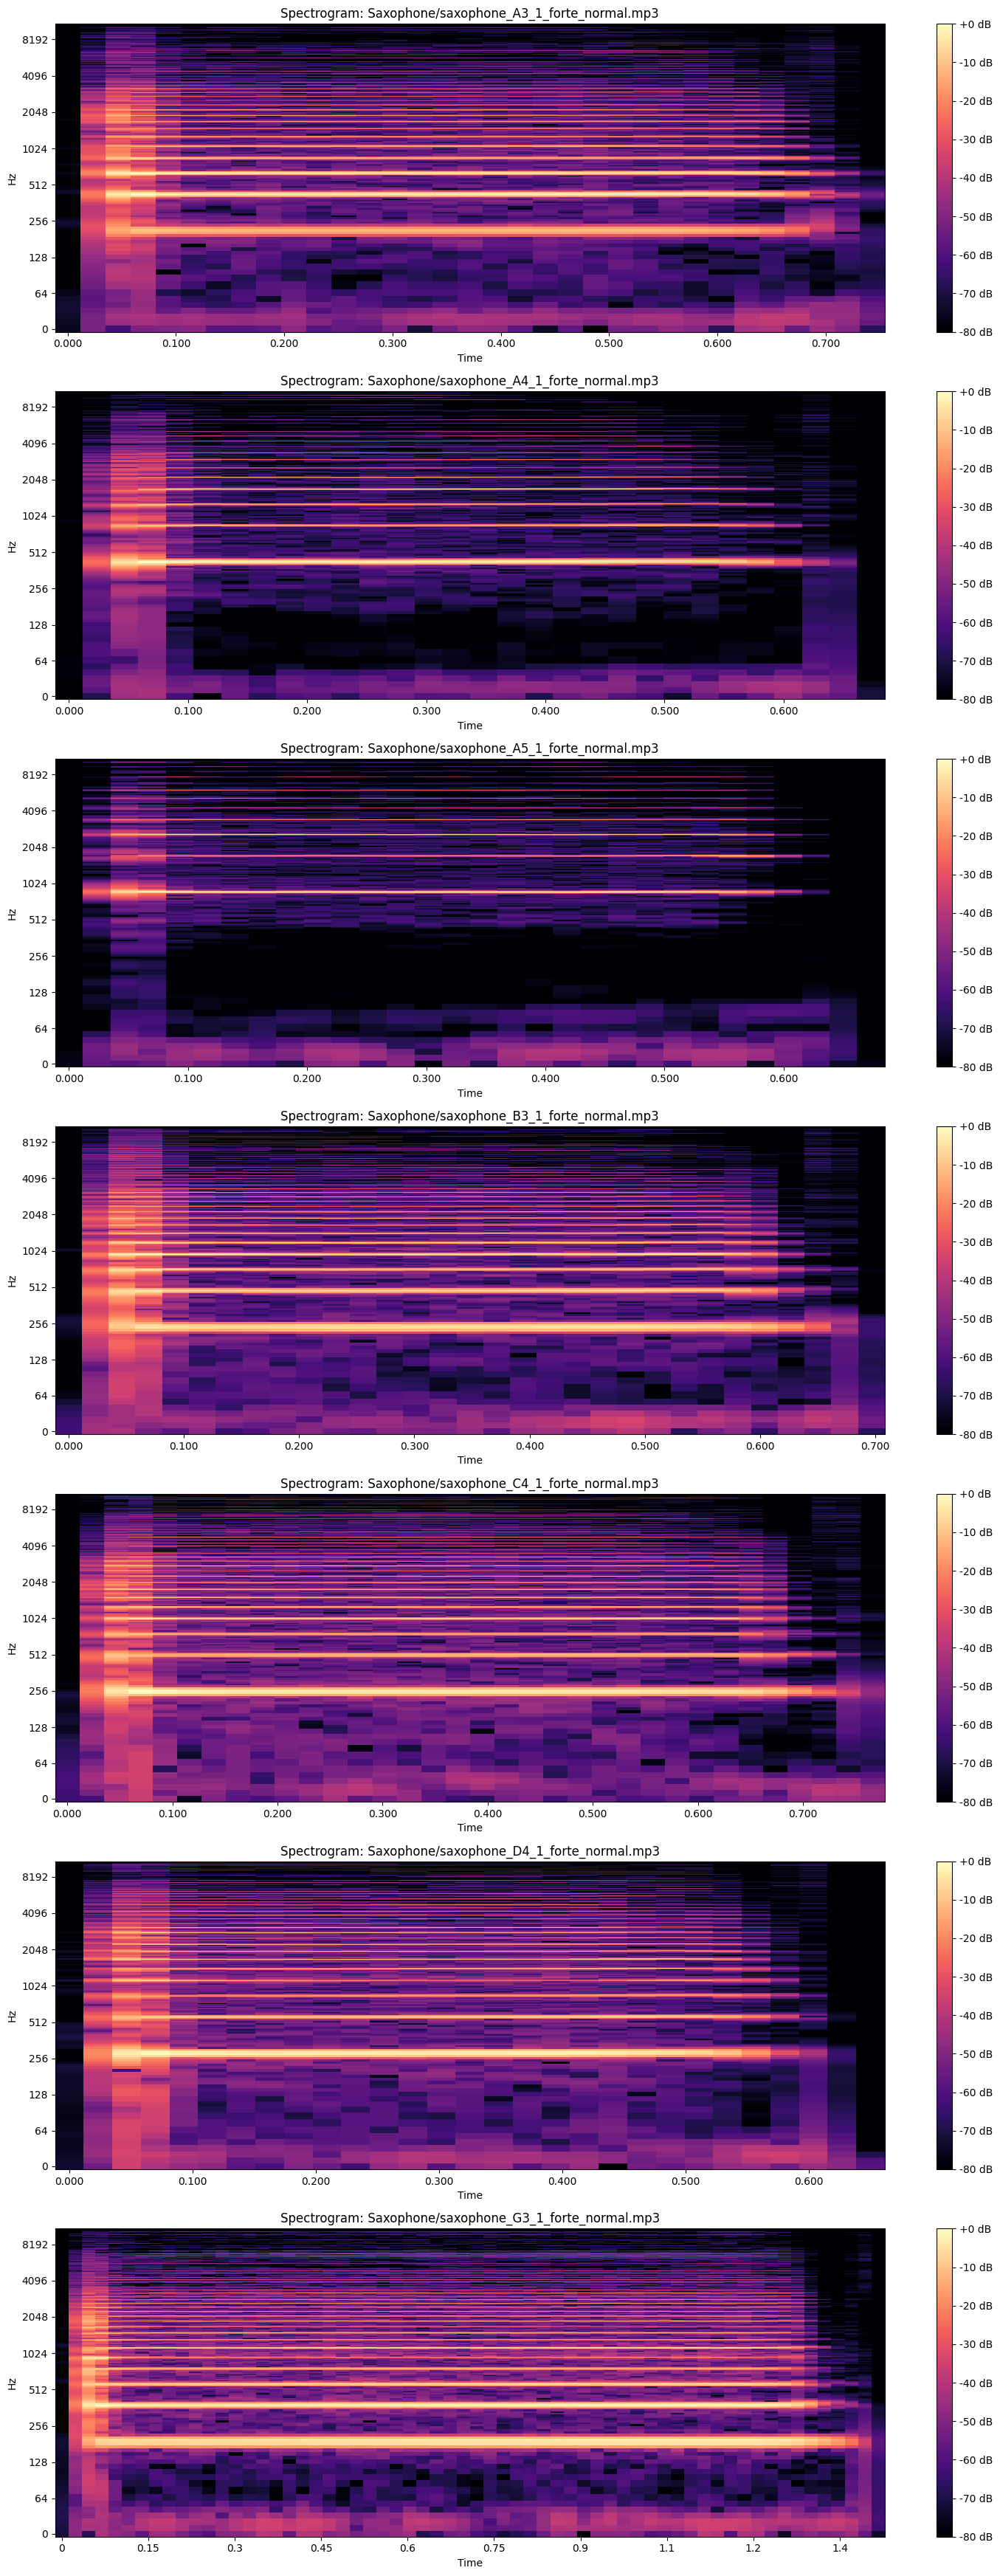

In [8]:
saxophone= 'Saxophone/saxophone_A3_1_forte_normal.mp3'
saxophone1= 'Saxophone/saxophone_A4_1_forte_normal.mp3'
saxophone2= 'Saxophone/saxophone_A5_1_forte_normal.mp3'
saxophone3= 'Saxophone/saxophone_B3_1_forte_normal.mp3'
saxophone4= 'Saxophone/saxophone_C4_1_forte_normal.mp3'
saxophone5= 'Saxophone/saxophone_D4_1_forte_normal.mp3'
saxophone6= 'Saxophone/saxophone_G3_1_forte_normal.mp3'

saxophones=[saxophone,saxophone1,saxophone2,saxophone3,saxophone4,saxophone5,saxophone6]
plot_multi_file_spectrograms(saxophones)

### Observations on the Results Obtained

As observed for the previous instruments (clarinet, banjo, and guitar), the harmonics are clearly visible, and the values for the characteristic frequencies of the notes are very pronounced. Similar to the other instruments, we can observe certain characteristics specific to the saxophone, particularly at the note's onset. Specifically, we see that at times close to 0, there are notably higher values across almost the entire spectrogram. This differs from the clarinet, which exhibits a more consistent beginning and ending, resulting in a more uniform spectrogram. This behavioral difference is due to the anatomical differences between the two instruments, which lead to different note stabilization times.

## Trumpet

The final analysis concerns the trumpet. As mentioned at the beginning of this analysis, we considered the same notes as those for the saxophone and clarinet to facilitate comparison between the wind instruments.

The cell below displays the spectrograms obtained from the analysis of the notes produced by the trumpet.

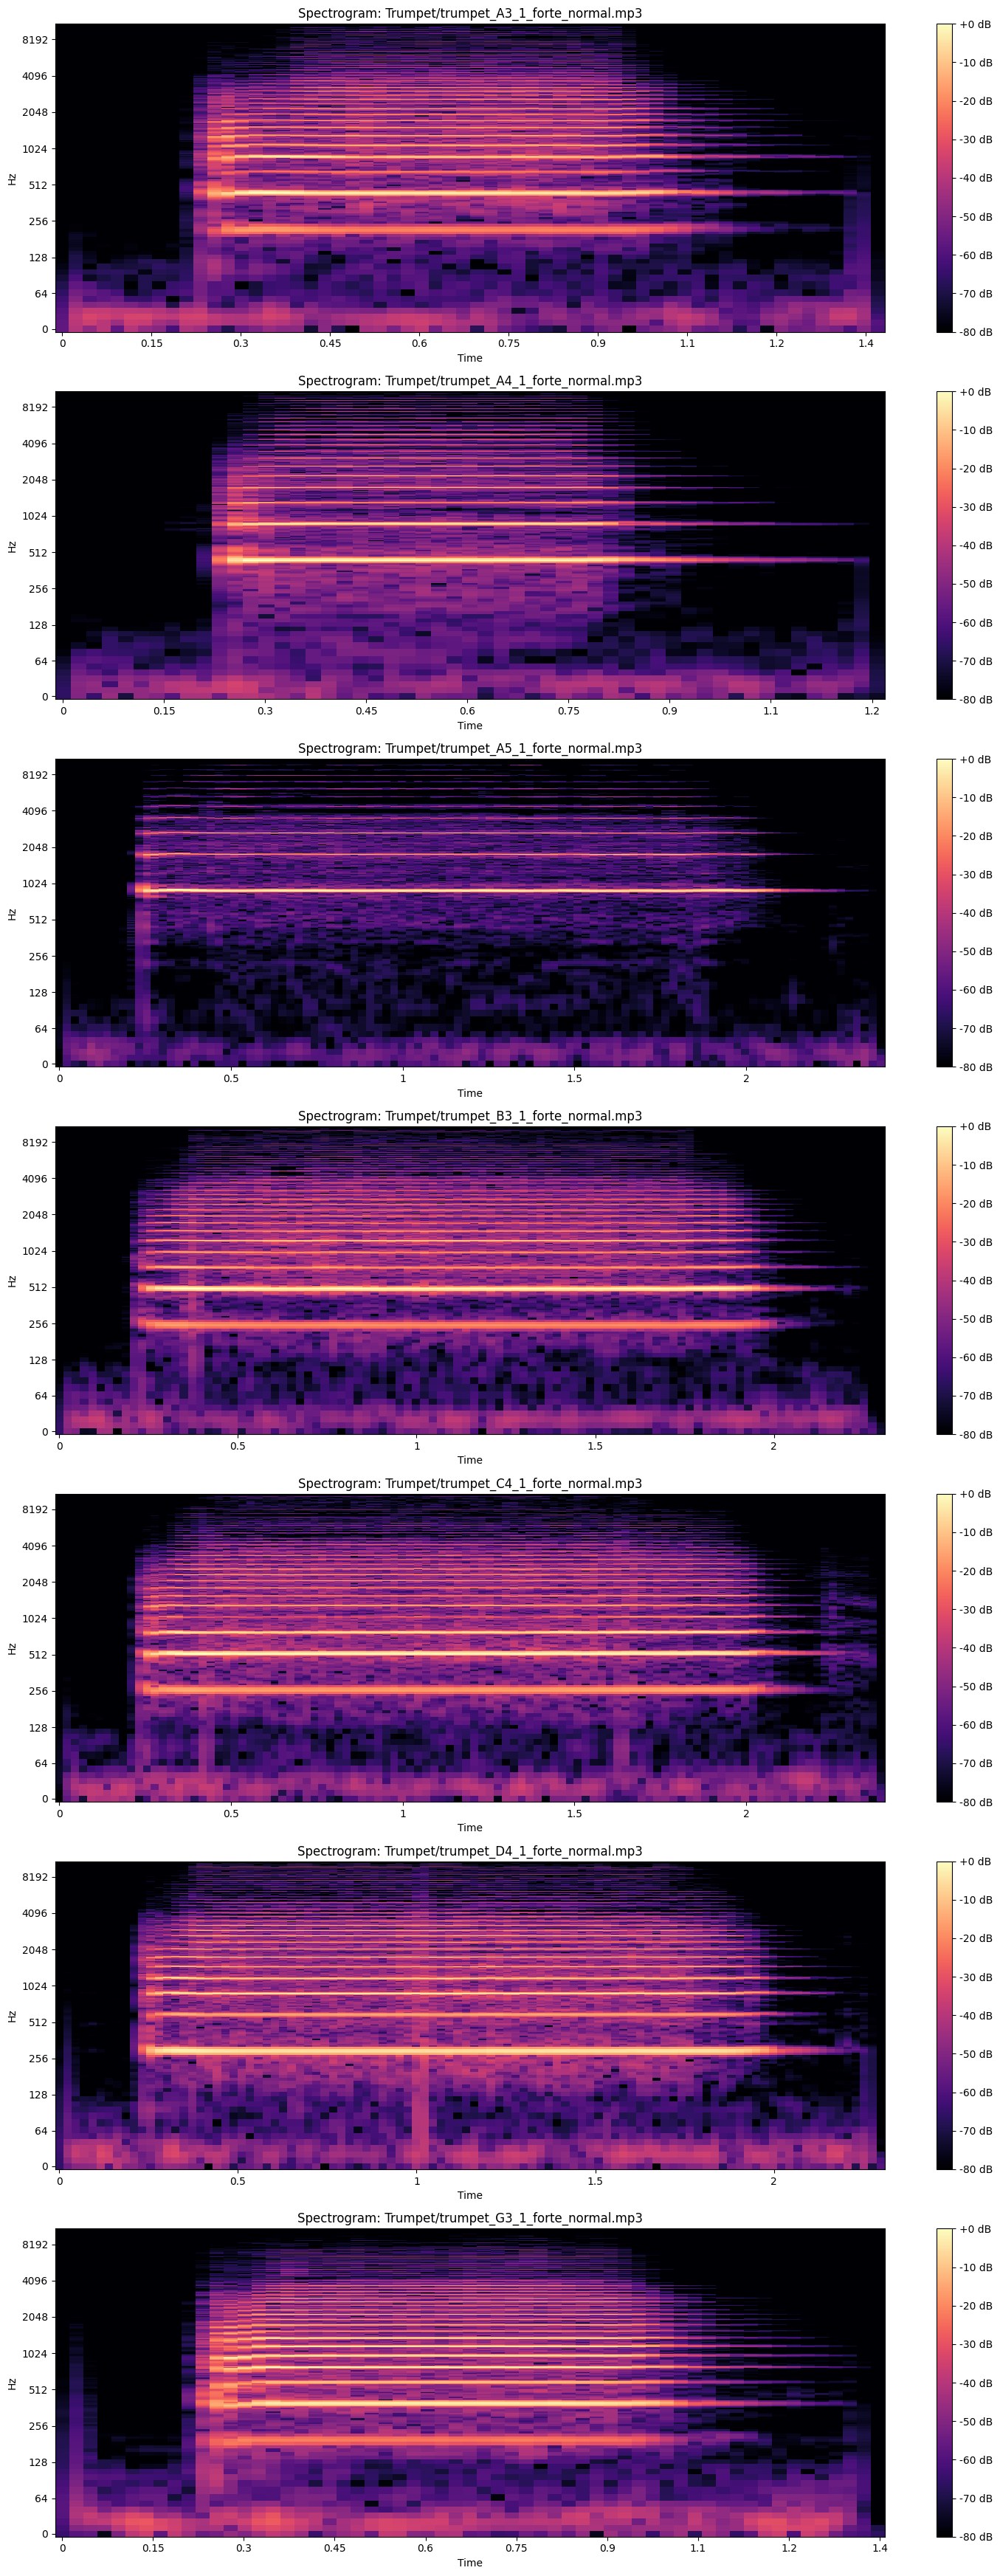

In [9]:
trumpet= 'Trumpet/trumpet_A3_1_forte_normal.mp3'
trumpet1= 'Trumpet/trumpet_A4_1_forte_normal.mp3'
trumpet2= 'Trumpet/trumpet_A5_1_forte_normal.mp3'
trumpet3= 'Trumpet/trumpet_B3_1_forte_normal.mp3'
trumpet4= 'Trumpet/trumpet_C4_1_forte_normal.mp3'
trumpet5= 'Trumpet/trumpet_D4_1_forte_normal.mp3'
trumpet6= 'Trumpet/trumpet_G3_1_forte_normal.mp3'

trumpets=[trumpet,trumpet1,trumpet2,trumpet3,trumpet4,trumpet5,trumpet6]

plot_multi_file_spectrograms(trumpets)

### Observations on the Results Obtained

The trumpet is the last instrument I considered. As observed in the trumpet's spectrograms, the harmonics are clearly visible, with higher values corresponding to the characteristic frequencies of the notes. We can identify some typical characteristics of the trumpet, such as a distinct attack compared to the saxophone or clarinet. The trumpet's note onset is gradual; specifically, at times close to 0, higher values are observed in the lower frequencies, and then, after a few hundredths of a second, higher values appear in the higher frequencies. This behavior is attributed to the instrument's anatomy, where the mouthpiece and overall structure influence this pattern.

### Conclusion and Final Considerations

We can observe several differences from the spectrograms. First, there are distinctions between string and wind instruments. In string instruments, the harmonics are more pronounced, and the frequencies between the harmonics are less prominent, likely due to the instrument's construction. The sound in string instruments is produced by a vibrating string, allowing for greater control. For instance, the guitar's resonance chamber filters the sound, resulting in cleaner spectrograms with more visible harmonics. In wind instruments, the note is produced by the vibration of an air column, leading to less controllable and potentially noisier sound. While harmonics are still visible, the spectrograms appear less clean.

Focusing on the two string instruments considered, we note differences between them. Despite using the same notes played in a sustained manner, the banjo's notes have a shorter duration than the guitar's. This difference is attributed to their anatomical variations. The banjo's open resonance chamber with a metal top facilitates rapid note decay. Conversely, the guitar's closed, typically wooden, resonance chamber allows for longer note durations. Material differences in the strings might also contribute, but these are not discernible from the spectrograms.

Turning to wind instruments, having already identified significant differences from string instruments, we now compare them amongst themselves. The trumpet exhibits a more abrupt attack, visible as very low values across most frequencies near time 0, except for the lower frequencies (this is due to the initial build-up of air pressure before the higher harmonics resonate). Conversely, the saxophone displays the opposite behavior, with high values, including higher frequencies, near time 0. This difference stems from their anatomical designs. The saxophone's vibrating mouthpiece produces a sound with higher frequencies from the onset. The trumpet's different mouthpiece, where sound is generated by lip vibrations, results in higher lower frequencies during note stabilization. The clarinet, despite sharing a mouthpiece with the saxophone, exhibits a more uniform spectrogram in terms of note attack. Its unique body structure influences its note stabilization. The clarinet is also characterized by its prominent odd-frequency harmonics, a distinctive pattern.

In all spectrograms, higher values are often observed in the lower frequencies. This could be due to electrical noise between 50 Hz and 60 Hz, prevalent in many countries. Alternatively, it might be caused by the microphone's proximity during recording, known as the proximity effect (explanation available here: https://www.audio-technica.com/en-us/support/what-is-proximity-effect#:~:text=Answer%3A%20Proximity%20effect%20is%20the,response%20of%20a%20directional%20microphone.).

Each instrument possesses unique characteristics, visible in their spectrograms. These characteristics vary based on instrument anatomy and player technique (e.g., breath control in wind instruments).

While spectrograms reveal differences between instruments, a more precise classification would benefit from detailed anatomical information and player-specific characteristics.